# Climate Risk & Human Development - project walkthrough

This notebook tells the story of the project step by step. It does **not** contain the
pipeline itself: the real code lives in `src/cro/` and is run with the `cro` command. Here
we **import the same functions** and show what they do on the final data.

**Question.** Are the regions with the most extreme climate also the regions with the lowest
human development? We test it on 105 admin-1 regions in France, India and the United States.

**How to run it.** From the project folder:

```bash
pip install -e . jupyter
jupyter notebook notebooks/exploration.ipynb
```

The notebook only needs `data/processed/dashboard_regions.parquet`, which is in the
repository, so it works right after `git clone` (no download needed).

## 1. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Functions from the project package (src/cro/)
from cro.utils import load_geo_table, percentile_rank
from cro.analysis.tests import hazard_development_test, test_rank_stability
from cro.analysis.regression import MODELS, fit_model, country_slopes
from cro.viz import theme

# The notebook can be started from the project root or from notebooks/.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

regions = load_geo_table(ROOT / "data" / "processed" / "dashboard_regions.parquet")
COUNTRY_NAMES = {"FRA": "France", "IND": "India", "USA": "United States"}
theme.apply_style()
pd.set_option("display.precision", 3)

print(f"{len(regions)} regions, {regions['iso3'].nunique()} countries, "
      f"{regions['population'].sum() / 1e9:.2f} billion people")

105 regions, 3 countries, 1.80 billion people


## 2. The data

One row per region. The table joins four open sources:

| Columns | Source |
|---|---|
| region polygons | geoBoundaries |
| `hd35_area`, `tr25_area`, `cdd_area`, `wbal_area`, `rx1d_area`, `r50_area` | NASA POWER daily climate, mean 2004-2023 |
| `population` | GHS-POP 2020 |
| `shdi` | Global Data Lab, Subnational Human Development Index |

In [2]:
regions[["region_name", "iso3", "population", "hd35_area", "cdd_area", "rx1d_area", "shdi"]].head()

,region_name,iso3,population,hd35_area,cdd_area,rx1d_area,shdi
0,Île-de-France,FRA,1.209e+07,0.75,23.00,24.742,0.959
1,Centre-Val de Loire,FRA,2.558e+06,3.35,22.15,24.621,0.895
2,Bourgogne-Franche-Comté,FRA,2.806e+06,0.20,19.75,27.383,0.897
3,Normandie,FRA,3.264e+06,0.10,21.15,24.276,0.896
4,Hauts-de-France,FRA,5.844e+06,0.15,20.65,23.287,0.879


Number of regions, population and average climate per country:

In [3]:
summary = regions.groupby("iso3").agg(
    regions=("region_id", "count"),
    population_m=("population", lambda x: x.sum() / 1e6),
    heat_days=("hd35_area", "mean"),
    tropical_nights=("tr25_area", "mean"),
    longest_dry_spell=("cdd_area", "mean"),
    heaviest_rain_mm=("rx1d_area", "mean"),
    shdi_mean=("shdi", "mean"),
)
summary.round(2)

,regions,population_m,heat_days,tropical_nights,longest_dry_spell,heaviest_rain_mm,shdi_mean
iso3,,,,,,,
FRA,13,64.25,2.17,0.47,23.32,28.89,0.91
IND,36,1399.79,60.42,96.23,59.67,66.93,0.72
USA,56,339.04,11.25,31.60,24.83,50.47,0.93


**Reading.** India has many more hot days (about 60 per year above 35 °C) than the USA (about 11)
and France (about 2), and a lower average SHDI. A quick sanity check: the desert state of
Rajasthan should have many heat days and the monsoon coast of Kerala almost none.

In [4]:
regions.set_index("region_name").loc[["Rājasthān", "Kerala"], ["hd35_area", "rx1d_area"]]

,hd35_area,rx1d_area
region_name,,
Rājasthān,169.082,45.393
Kerala,0.000,93.547


## 3. Building the index

Every indicator becomes a **percentile rank** between 0 and 1. Example with five values:
the smallest gets 0.2, the largest gets 1.0, whatever the units.

In [5]:
example = pd.Series([2, 11, 60, 169, 0], index=["France", "USA", "India", "Rajasthan", "Kerala"])
pd.DataFrame({"heat days": example, "percentile rank": percentile_rank(example)})

,heat days,percentile rank
France,2,0.4
USA,11,0.6
India,60,0.8
Rajasthan,169,1.0
Kerala,0,0.2


Then (code in `src/cro/features/build.py`):

```
Hazard        = mean(heat, dry, wet)        each sub-score = mean rank of two indicators
Exposure      = rank(population)
Vulnerability = 1 - rank(SHDI)
Risk          = Hazard x Exposure x Vulnerability
```

We check that the saved risk score really is the product of its three parts:

In [6]:
data = regions.dropna(subset=["risk_equal"])
recomputed = data["hazard_equal"] * data["exposure_score"] * data["vulnerability"]
print("largest difference:", float((recomputed - data["risk_equal"]).abs().max()))

largest difference: 0.0


## 4. Where is the risk highest?

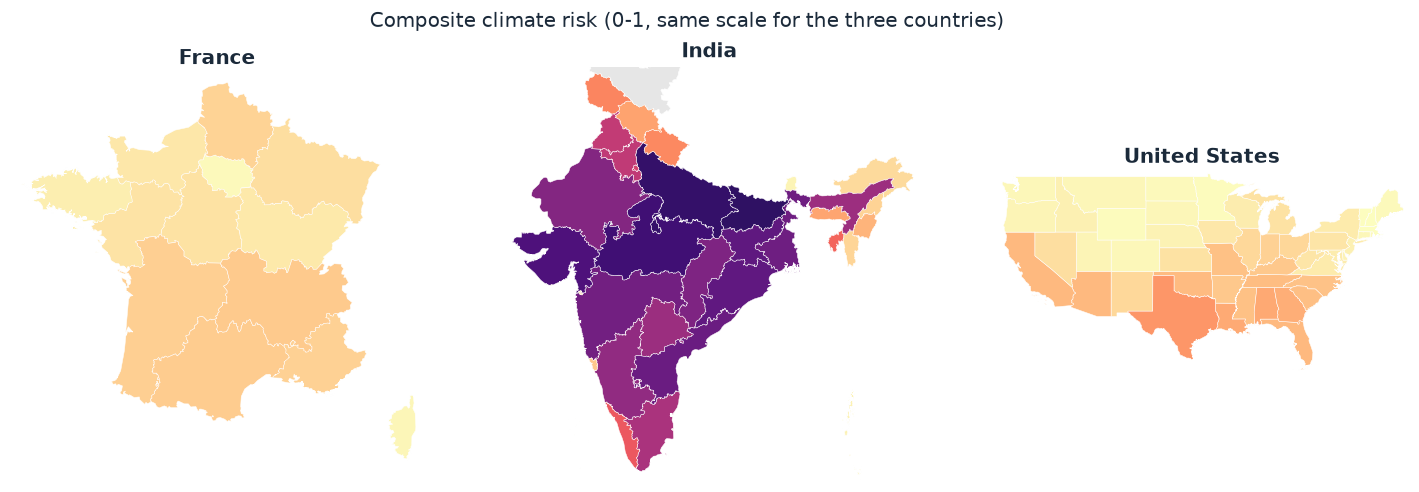

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
bounds = {"FRA": (-5.5, 9.8, 41, 51.3), "IND": (67.5, 97.5, 7.5, 35.5), "USA": (-125.5, -66.5, 24, 49.5)}
for ax, iso3 in zip(axes, ["FRA", "IND", "USA"]):
    regions[regions["iso3"] == iso3].plot(column="risk_equal", cmap="magma_r", vmin=0, vmax=1,
                                          ax=ax, edgecolor="white", linewidth=0.3,
                                          missing_kwds={"color": "#e6e6e6"})
    ax.set_xlim(*bounds[iso3][:2]); ax.set_ylim(*bounds[iso3][2:])
    ax.set_title(COUNTRY_NAMES[iso3]); ax.axis("off")
fig.suptitle("Composite climate risk (0-1, same scale for the three countries)")
plt.show()

On one shared scale, the top 10 is entirely Indian:

In [8]:
regions.nlargest(10, "risk_equal")[
    ["region_name", "iso3", "hazard_equal", "exposure_score", "vulnerability", "risk_equal"]
]

,region_name,iso3,hazard_equal,exposure_score,vulnerability,risk_equal
82,Bihār,IND,0.849,0.981,0.990,0.825
73,Uttar Pradesh,IND,0.844,1.000,0.965,0.815
96,Madhya Pradesh,IND,0.860,0.962,0.949,0.786
76,Gujarāt,IND,0.913,0.933,0.889,0.757
90,Jhārkhand,IND,0.830,0.876,0.980,0.713
81,Odisha,IND,0.814,0.905,0.965,0.711
86,Andhra Pradesh,IND,0.833,0.914,0.899,0.685
80,West Bengal,IND,0.763,0.971,0.909,0.674
70,Mahārāshtra,IND,0.871,0.990,0.773,0.667
75,Chhattīsgarh,IND,0.833,0.829,0.919,0.635


Inside each country (column `rank_in_country`), the top 3 regions are:

In [9]:
(regions[regions["rank_in_country"] <= 3]
 .sort_values(["iso3", "rank_in_country"])
 [["iso3", "rank_in_country", "region_name", "risk_equal"]])

,iso3,rank_in_country,region_name,risk_equal
10,FRA,1.0,Auvergne-Rhône-Alpes,0.111
9,FRA,2.0,Occitanie,0.109
8,FRA,3.0,Nouvelle-Aquitaine,0.102
82,IND,1.0,Bihār,0.825
73,IND,2.0,Uttar Pradesh,0.815
96,IND,3.0,Madhya Pradesh,0.786
28,USA,1.0,Texas,0.223
30,USA,2.0,Alabama,0.182
18,USA,3.0,Louisiana,0.177


## 5. H1 - More hazard, less development?

Spearman rank correlation between hazard and SHDI, on all regions and then country by country.
We call `hazard_development_test` from `src/cro/analysis/tests.py`.

In [10]:
h1 = pd.DataFrame(
    [hazard_development_test(regions, "ALL")]
    + [hazard_development_test(group, iso3) for iso3, group in regions.groupby("iso3")]
)
h1

,group,n_regions,spearman_rho,p_value,median_shdi_high_hazard,median_shdi_low_hazard
0,ALL,99,-0.589,1.387e-10,0.786,0.936
1,FRA,13,0.176,5.656e-01,0.908,0.898
2,IND,35,-0.483,3.266e-03,0.686,0.737
3,USA,51,-0.481,3.540e-04,0.923,0.942


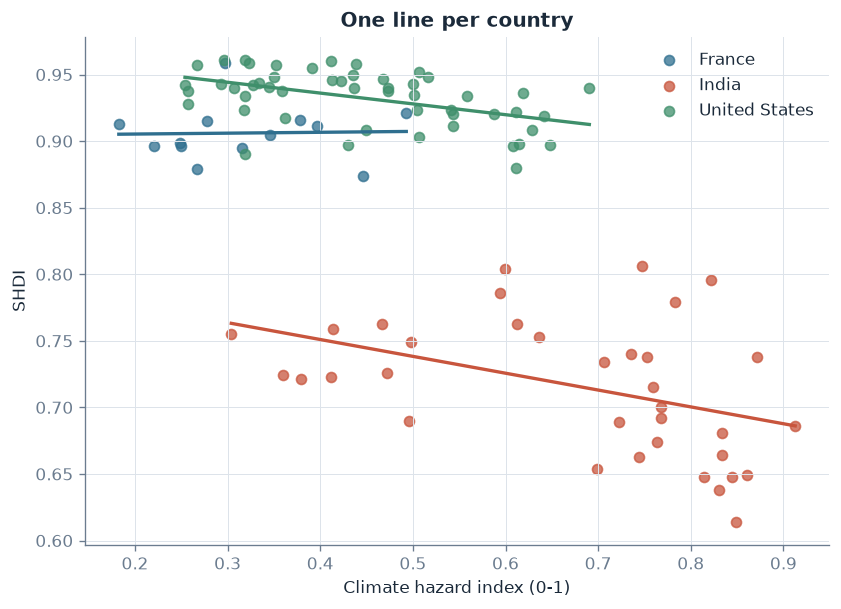

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
for iso3, group in regions.dropna(subset=["shdi"]).groupby("iso3"):
    color = theme.COUNTRY_COLORS[iso3]
    ax.scatter(group["hazard_equal"], group["shdi"], color=color, alpha=0.75, label=COUNTRY_NAMES[iso3])
    slope, intercept = np.polyfit(group["hazard_equal"], group["shdi"], 1)
    x = np.linspace(group["hazard_equal"].min(), group["hazard_equal"].max(), 20)
    ax.plot(x, intercept + slope * x, color=color, linewidth=2)
ax.set_xlabel("Climate hazard index (0-1)"); ax.set_ylabel("SHDI"); ax.legend()
ax.set_title("One line per country")
plt.show()

**Reading.** On all regions the correlation is strong (about −0.59), but the points form three
groups. Inside India and the USA the correlation is weaker (about −0.48) and in France there is
no clear link. So a large part of H1 is the difference between India and the two other countries.

## 6. H2 - Is it still true inside each country?

Two linear regressions (functions in `src/cro/analysis/regression.py`):

- **M1:** `shdi ~ hazard_equal`
- **M2:** `shdi ~ hazard_equal + C(iso3)` - one dummy per country, so only differences
  between regions of the *same* country are used.

In [12]:
model_data = regions.dropna(subset=["shdi", "hazard_equal"])
pd.DataFrame([fit_model(model_data, formula, name) for name, formula in MODELS])

,model,term,beta,std_error,p_value,ci_low,ci_high,n_obs,r_squared
0,M1 all regions,hazard_equal,-0.392,0.036,1.620e-27,-0.463,-0.321,99,0.479
1,M2 country effects,hazard_equal,-0.101,0.023,8.743e-06,-0.145,-0.056,99,0.914


In [13]:
country_slopes(model_data)

,iso3,n_regions,slope,std_error,p_value,ci_low,ci_high,r_squared
0,FRA,13,0.007,0.075,9.298e-01,-0.140,0.154,8.036e-04
1,IND,35,-0.127,0.040,1.365e-03,-0.204,-0.049,1.792e-01
2,USA,51,-0.081,0.022,2.724e-04,-0.125,-0.037,2.331e-01


**Reading.** The hazard coefficient goes from about −0.39 (M1) to about −0.10 (M2): roughly three
quarters of the link is between countries, but a smaller, significant link remains inside
countries. It is clear in India and the USA and absent in France (only 13 regions).

## 7. H3 - Is the ranking stable?

We compare the main index with two other versions: the simple mean of the three scores
(`additive`) and a version without population (`per_person` = hazard × vulnerability).

In [14]:
versions = pd.concat([
    regions[["region_id", f"rank_{v}"]].rename(columns={f"rank_{v}": "rank"}).assign(version=v)
    for v in ["equal", "additive", "per_person"]
])
test_rank_stability(versions.dropna(subset=["rank"]))

,version_a,version_b,n_regions,spearman_rho,same_in_top10
0,additive,equal,99,0.970,10
1,additive,per_person,99,0.893,9
2,equal,per_person,99,0.863,9


**Reading.** The rankings are strongly correlated and at least 9 of the top 10 regions are the
same in every pair. Even without population, the same Indian states lead: the result is not
only a size effect.

## 8. Conclusion

| Hypothesis | Result |
|---|---|
| H1 - more hazard, lower SHDI | Yes on all regions; weaker inside countries |
| H2 - still true inside countries | Yes in India and the USA, smaller effect; not in France |
| H3 - stable ranking | Yes |

These are **associations, not causes**. Neighbouring regions are similar, so the p-values are
probably too small; a spatial model would be the next step. The full method, the references and
all the limits are in the report: `outputs/report/report.html` (English) and
`outputs/report/report.fr.html` (French).